In [5]:
DATA_DIR = Path("/Users/drewburrier/Open-Oceanography/Data/318M20130321_nc_ctd/")

# 🌊 Open Oceanography: The Ocean Layer Cake

In this notebook, we are going to dive beneath the surface and look at the internal structure of the ocean. Using real Conductivity, Temperature, and Depth (CTD) data from the World Ocean Circulation Experiment (eWOCE), we will visualize the thermocline, halocline, and pycnocline.

## 📦 Environment Setup
To ensure all required dependencies are installed, follow these steps:

### **🔹 Using Conda (Recommended)**
If you have **Conda** installed, create a dedicated environment. Note that we are adding `gsw` (Gibbs SeaWater), which is the standard library oceanographers use to calculate seawater density!

conda create -n ocean_env python=3.9
conda activate ocean_env
conda install -c conda-forge xarray netcdf4 matplotlib cartopy cmocean gsw

## 📍 Instructions for Downloading eWOCE Data

Before running this notebook, you **must manually download the CTD dataset**. We are getting our data from the CLIVAR and Carbon Hydrographic Data Office (CCHDO).

1. **Go to the database**: [CCHDO Pacific Transects](https://cchdo.ucsd.edu/search?bbox=120,-60,-75,65)
2. **Find the cruise**: Look for the specific transect you want to plot (like the Japan to California line, or the P16 North and South legs).
3. **Download the data**: Select the cruise and download the **`nc.zip`** file. This package contains the NetCDF formatted data we need.
4. **Extract the files**: Unzip the downloaded folder.
5. **Move the folder**: Place the unzipped folder directly into your Open-Oceanography `Data` directory so this notebook can find it.

Once the folders are in place, you are ready to run the cells below!

In [19]:
# ====================================================================
# ⚙️ BLOCK 1: IMPORTS AND HELPER FUNCTIONS
# ====================================================================

from pathlib import Path
import re
import warnings
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib import colors
import gsw

warnings.filterwarnings("ignore")

# Colormaps
cmap_s_abs = plt.cm.viridis
cmap_rho = plt.cm.GnBu

try:
    import cmocean
    cmap_anom = cmocean.cm.balance
    cmap_s_shallow = cmocean.cm.balance
except ImportError:
    cmap_anom = plt.cm.RdBu_r
    cmap_s_shallow = plt.cm.RdBu_r

PRESS_GRID = np.arange(0, 6001, 10)

def open_nc(fp):
    last_err = None
    for eng in ("netcdf4", "scipy", "h5netcdf"):
        try:
            with warnings.catch_warnings():
                warnings.simplefilter("ignore")
                return xr.open_dataset(fp, engine=eng, decode_cf=True, mask_and_scale=True)
        except Exception as e:
            last_err = e
    raise last_err

def get_var(ds, candidates):
    for name in candidates:
        if name in ds:
            arr = ds[name]
            try:
                return np.asarray(arr.load().to_numpy()).squeeze()
            except Exception:
                return np.asarray(arr.values).squeeze()
    raise KeyError(f"Missing any of {candidates}")

def get_lat(ds):
    for k in ["LATITUDE", "latitude", "lat", "station_latitude"]:
        if k in ds:
            return float(np.atleast_1d(ds[k].values).ravel()[0])
    for k in ["LATITUDE", "latitude", "geospatial_lat_min"]:
        if k in ds.attrs:
            return float(ds.attrs[k])
    raise KeyError("latitude not found")

def get_lon(ds):
    for k in ["LONGITUDE", "longitude", "lon", "station_longitude"]:
        if k in ds:
            v = float(np.atleast_1d(ds[k].values).ravel()[0])
            return v - 360 if v > 180 else v
    for k in ["LONGITUDE", "longitude", "geospatial_lon_min"]:
        if k in ds.attrs:
            v = float(ds.attrs[k])
            return v - 360 if v > 180 else v
    raise KeyError("longitude not found")

def mask_by_flag(ds, base):
    for cand in [f"{base}_FLAG_W", f"{base}_QC", f"{base}_flag"]:
        if cand in ds:
            f = np.atleast_1d(ds[cand].values).astype(float)
            return np.isin(f, [1, 2])
    return None

def interp_cast(p, x):
    p = np.asarray(p).astype(float).squeeze()
    x = np.asarray(x).astype(float).squeeze()
    m = np.isfinite(p) & np.isfinite(x)
    if m.sum() < 2:
        return np.full(PRESS_GRID.shape, np.nan)
    p, x = p[m], x[m]
    idx = np.argsort(p)
    p, x = p[idx], x[idx]
    out = np.full(PRESS_GRID.shape, np.nan)
    valid = (PRESS_GRID >= p.min()) & (PRESS_GRID <= p.max())
    out[valid] = np.interp(PRESS_GRID[valid], p, x)
    return out

def haversine_km(lat1, lon1, lat2, lon2):
    r = 6371.0
    dlat = np.deg2rad(lat2 - lat1)
    dlon = np.deg2rad(lon2 - lon1)
    a = np.sin(dlat / 2) ** 2 + np.cos(np.deg2rad(lat1)) * np.cos(np.deg2rad(lat2)) * np.sin(dlon / 2) ** 2
    return 2 * r * np.arcsin(np.sqrt(a))

# --- MISSING FUNCTIONS RESTORED ---
def parse_station_from_name(path):
    m = re.search(r"_(\d{5})_(\d{5})_ctd\.nc$", path.name)
    if m:
        return int(m.group(1)), int(m.group(2))
    return None, None

def get_station_number(ds, path):
    for name in ["STNNBR", "station", "station_number", "STATION_NUMBER"]:
        if name in ds:
            try:
                return int(np.atleast_1d(ds[name].values).ravel()[0])
            except Exception:
                pass
    stn, _cast = parse_station_from_name(path)
    return stn

print("✅ Block 1 Executed: Imports and Helper Functions are ready.")

✅ Block 1 Executed: Imports and Helper Functions are ready.


In [36]:
# ====================================================================
# 📂 BLOCK 2: READ AND PROCESS ALL TRANSECTS (Japan-CA + P16)
# ====================================================================

# 1. Define Directories
dirs = {
    "EW": [Path("/Users/drewburrier/Open-Oceanography/Data/318M20130321_nc_ctd/")],
    "NS": [Path("/Users/drewburrier/Open-Oceanography/Data/325020060213_nc_ctd/"), 
           Path("/Users/drewburrier/Open-Oceanography/Data/33RR20050109_nc_ctd/")]
}

def load_transect(dir_list, is_ns=False):
    stations = []
    skipped = 0
    all_files = []
    
    for d in dir_list:
        all_files.extend(sorted([p for p in d.glob("*ctd.nc") if p.is_file() and p.stat().st_size > 1024]))
    
    print(f"📂 Processing {len(all_files)} files...")
    
    for fp in all_files:
        ds = open_nc(fp)
        # CRITICAL: Verify it's an xarray Dataset
        if not isinstance(ds, xr.Dataset):
            continue
            
        try:
            p = get_var(ds, ["CTDPRS", "PRES", "pressure", "PRES_REL"])
            t = get_var(ds, ["CTDTMP", "TEMP", "temperature"])
            sp = get_var(ds, ["CTDSAL", "PSAL", "salinity", "SALNTY"])
            
            m_s = mask_by_flag(ds, "CTDSAL") or mask_by_flag(ds, "PSAL")
            sp = np.where(m_s, sp, np.nan) if m_s is not None else sp
            
            lat = get_lat(ds)
            lon = get_lon(ds)
            stn = get_station_number(ds, fp)
            
            stations.append({"stn": stn, "lat": lat, "lon": lon, "SP": interp_cast(p, sp), "T": interp_cast(p, t)})
        except Exception as e:
            skipped += 1
            print(f"Skip {fp.name}: {e}")
            
    if len(stations) < 2:
        raise RuntimeError(f"Not enough valid casts to build a section (Found {len(stations)})")

    # SORTING: Geographic for North-South (P16), Station Number for EW
    if is_ns:
        stations.sort(key=lambda s: s["lat"])
    else:
        stations.sort(key=lambda s: (999999 if s["stn"] is None else s["stn"]))
    
    dists = [0.0]
    for i in range(1, len(stations)):
        d = haversine_km(stations[i-1]["lat"], stations[i-1]["lon"], stations[i]["lat"], stations[i]["lon"])
        dists.append(dists[-1] + d)
    X = np.array(dists)
    
    SP = np.stack([s["SP"] for s in stations], axis=1)
    TT = np.stack([s["T"] for s in stations], axis=1)
    LAT = np.tile(np.array([s["lat"] for s in stations])[None, :], (PRESS_GRID.size, 1))
    LON = np.tile(np.array([s["lon"] for s in stations])[None, :], (PRESS_GRID.size, 1))
    
    SA = gsw.SA_from_SP(SP, PRESS_GRID[:, None], LON, LAT)
    CT = gsw.CT_from_t(SA, TT, PRESS_GRID[:, None])
    sigma0 = gsw.sigma0(SA, CT)
    
    print(f"✅ Processed {len(stations)} stations. Skipped {skipped}.")
    # Return stations list so it can be used for mapping
    return X, SP, sigma0, stations

# 2. Run Processing
print("--- Japan-California (EW) ---")
X_ew, SP_ew, Sig_ew, stations_ew = load_transect(dirs["EW"], is_ns=False)

print("--- North-South (P16) ---")
X_ns, SP_ns, Sig_ns, stations_ns = load_transect(dirs["NS"], is_ns=True)

--- Japan-California (EW) ---
📂 Processing 159 files...
✅ Processed 159 stations. Skipped 0.
--- North-South (P16) ---
📂 Processing 199 files...
✅ Processed 199 stations. Skipped 0.


### 🍰 Visualizing the Layer Cake
In the lesson above, we discussed how solar heating creates a distinct vertical structure. The plot below visualizes the **Zonal Transect** across the Pacific. Because we are moving roughly along the same latitude, the solar heating is constant. Look for the massive, uniform volume of the deep ocean and the sharp horizontal barrier of the thermocline near the surface.

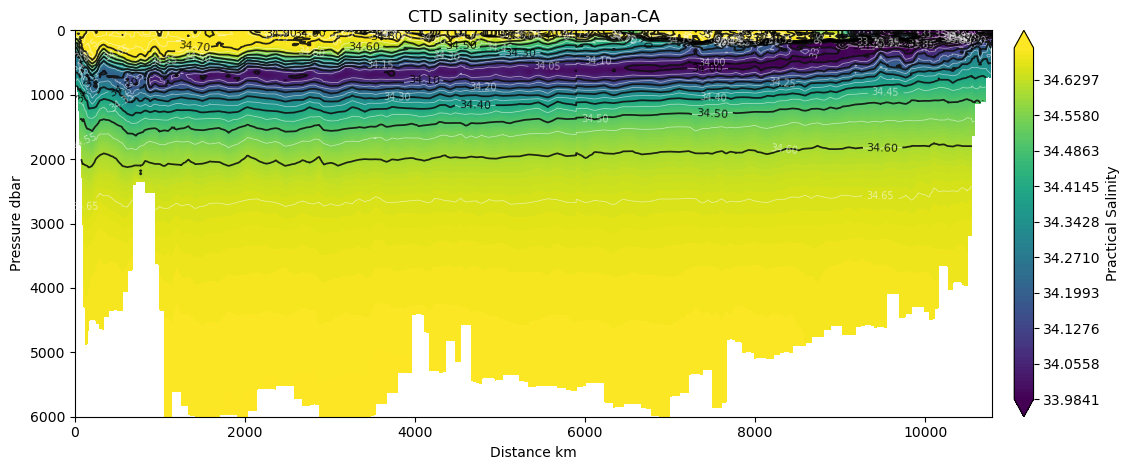

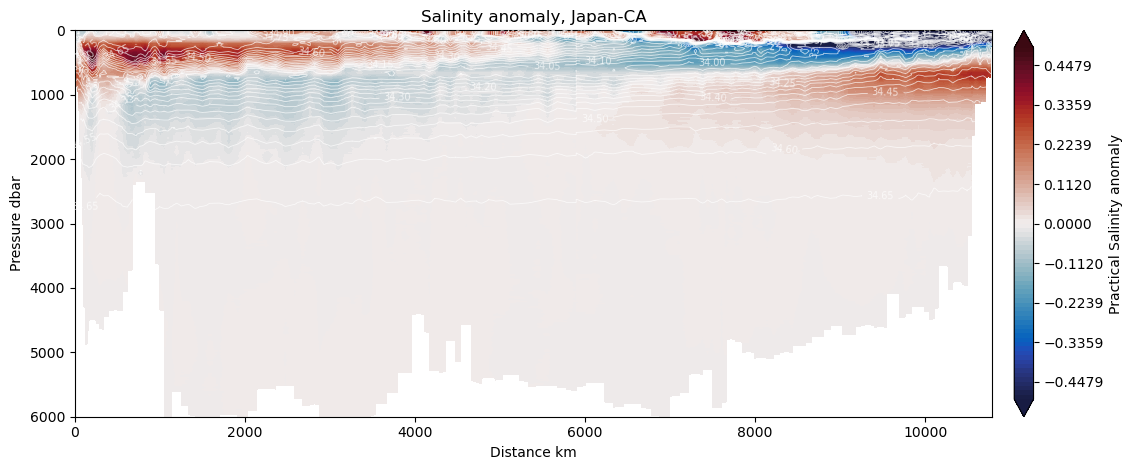

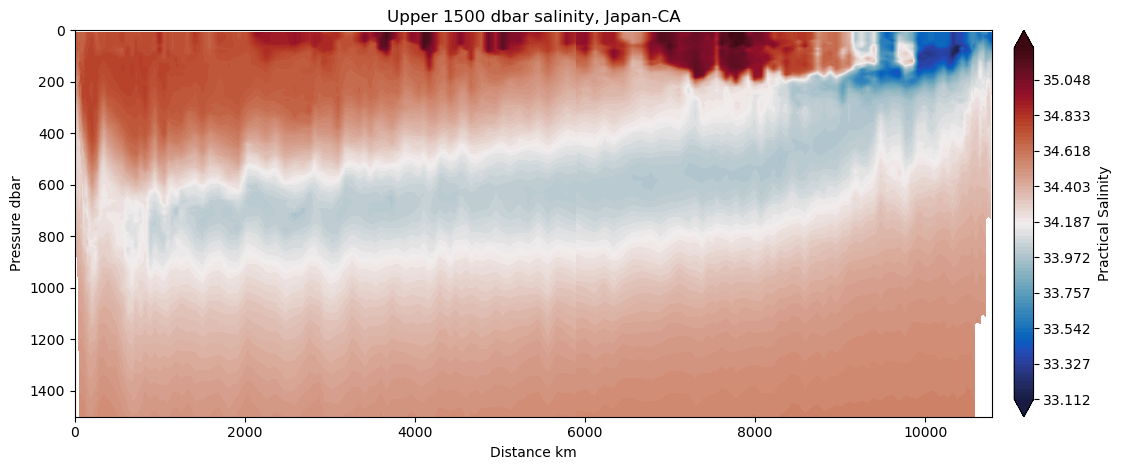

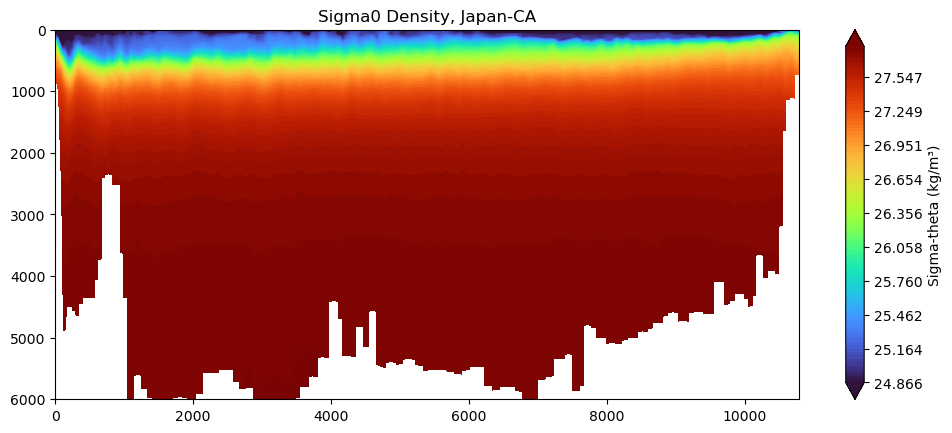

In [8]:
# ====================================================================
# 📊 BLOCK 3: GENERATE EAST-WEST (JAPAN-CA) PLOTS
# ====================================================================

# Map the EW variables to the names the plotter expects
SP = SP_ew
X = X_ew
sigma0 = Sig_ew

# [Insert your plotting functions here: plot_section_abs, plot_section_anom]

# --------------------------------------------------------------------
# 1. Full depth straight salinity
# --------------------------------------------------------------------
sp_vals = SP[np.isfinite(SP)]
smin, smax = float(sp_vals.min()), float(sp_vals.max())
iso_thin = np.arange(np.floor(smin * 20) / 20, np.ceil(smax * 20) / 20 + 1e-6, 0.05)
iso_heavy = np.arange(np.floor(smin * 10) / 10, np.ceil(smax * 10) / 10 + 1e-6, 0.10)

# Replace build_piecewise_levels with a standard linspace if not defined
sal_levels_full = np.linspace(np.percentile(sp_vals, 1), np.percentile(sp_vals, 95), 100)

plot_section_abs(X, PRESS_GRID, SP, sal_levels_full, cmap_s_abs, 
                 "CTD salinity section, Japan-CA", "Practical Salinity", 
                 thin_contours=iso_thin, heavy_contours=iso_heavy)

# --------------------------------------------------------------------
# 2. Full depth salinity anomaly
# --------------------------------------------------------------------
SP_ref = np.nanmedian(SP, axis=1, keepdims=True)
SP_anom = SP - SP_ref
alim = float(np.percentile(np.abs(SP_anom[np.isfinite(SP_anom)]), 99))
plot_section_anom(X, PRESS_GRID, SP_anom, alim, "Salinity anomaly, Japan-CA", "Practical Salinity anomaly", SP, iso_thin)

# --------------------------------------------------------------------
# 3. Upper 1500 dbar salinity
# --------------------------------------------------------------------
mask_sh = PRESS_GRID <= 1500
plot_section_abs(X, PRESS_GRID[mask_sh], SP[mask_sh, :], np.linspace(np.nanmin(SP[mask_sh]), np.nanmax(SP[mask_sh]), 100), 
                 cmap_s_shallow, "Upper 1500 dbar salinity, Japan-CA", "Practical Salinity")

# --------------------------------------------------------------------
# 4. Sigma0 Density
# --------------------------------------------------------------------
sg_vals = sigma0[np.isfinite(sigma0)]
sg_lo, sg_hi = np.percentile(sg_vals, [1, 99])
rho_levels = np.linspace(sg_lo, sg_hi, 100)

plt.figure(figsize=(12, 4.8))
cf = plt.contourf(X, PRESS_GRID, sigma0, levels=rho_levels, cmap=plt.cm.turbo, extend="both")
plt.gca().invert_yaxis()
plt.colorbar(cf, label="Sigma-theta (kg/m³)")
plt.title("Sigma0 Density, Japan-CA")
plt.show()

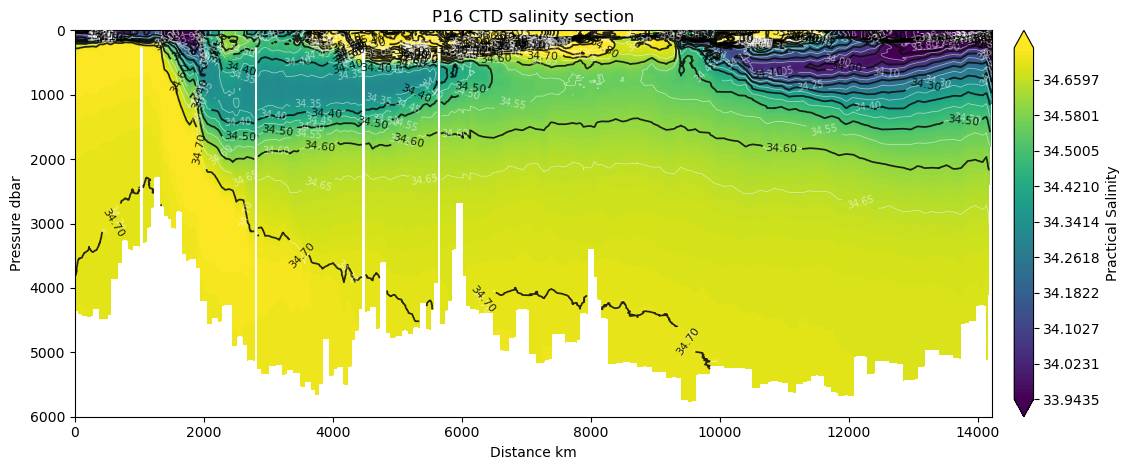

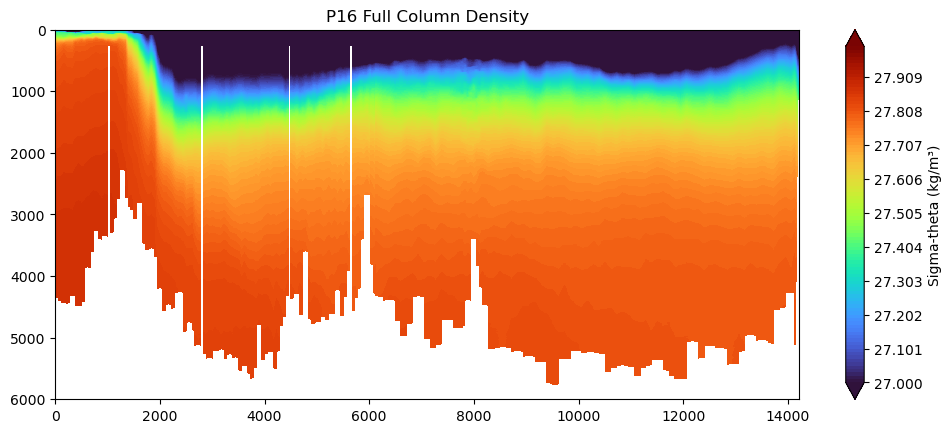

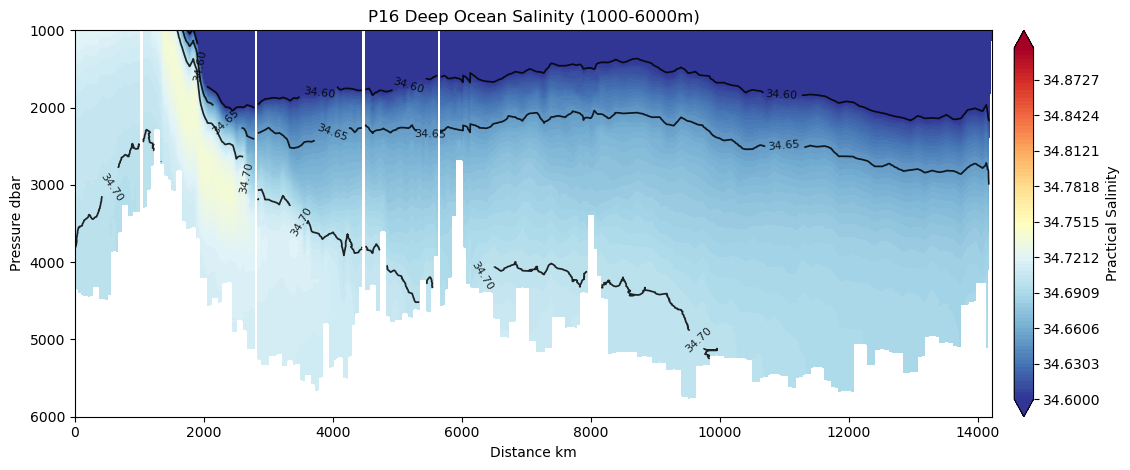

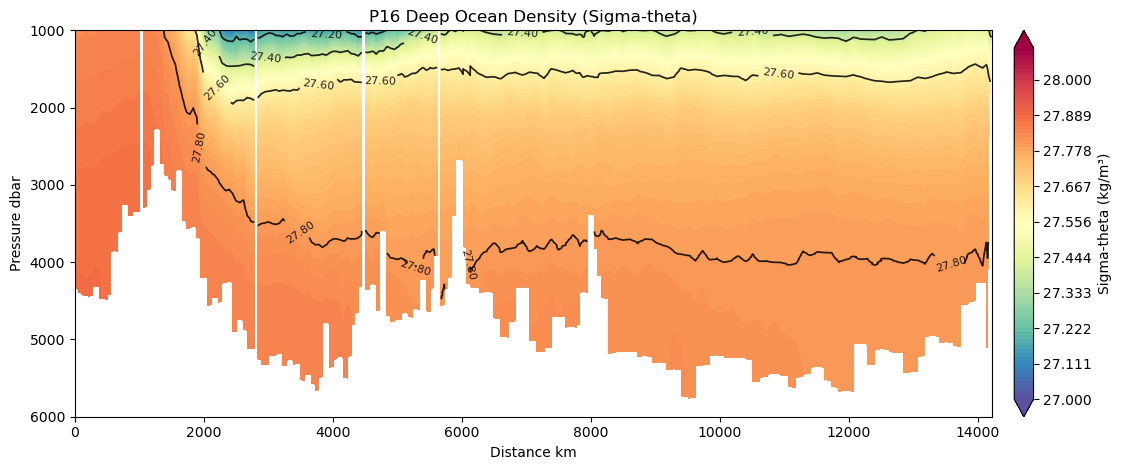

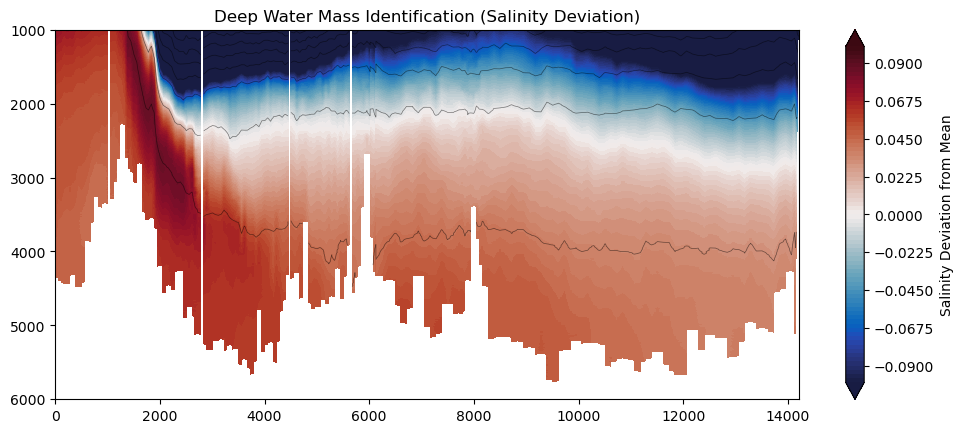

In [34]:
# ====================================================================
# 📊 BLOCK 4: NORTH-SOUTH (P16) PLOTS (FULL COLUMN + DEEP FOCUS)
# ====================================================================

SP = SP_ns
X = X_ns
sigma0 = Sig_ns

# --- PART 1: FULL WATER COLUMN (Baseline) ---
sp_vals = SP[np.isfinite(SP)]
smin, smax = float(sp_vals.min()), float(sp_vals.max())
iso_thin = np.arange(np.floor(smin * 20) / 20, np.ceil(smax * 20) / 20 + 1e-6, 0.05)
iso_heavy = np.arange(np.floor(smin * 10) / 10, np.ceil(smax * 10) / 10 + 1e-6, 0.10)

sal_levels_full = np.linspace(np.percentile(sp_vals, 1), np.percentile(sp_vals, 95), 100)

plot_section_abs(X, PRESS_GRID, SP, sal_levels_full, cmap_s_abs, 
                 "P16 CTD salinity section", "Practical Salinity", 
                 thin_contours=iso_thin, heavy_contours=iso_heavy)

# Density
plt.figure(figsize=(12, 4.8))
cf = plt.contourf(X, PRESS_GRID, sigma0, levels=np.linspace(27, 28, 100), cmap=plt.cm.turbo, extend="both")
plt.gca().invert_yaxis()
plt.colorbar(cf, label="Sigma-theta (kg/m³)")
plt.title("P16 Full Column Density")
plt.show()

# --- PART 2: DEEP WATER MASS FOCUS (1000m - 6000m) ---
mask_deep = (PRESS_GRID >= 1000) & (PRESS_GRID <= 6000)
P_deep = PRESS_GRID[mask_deep]
SP_deep = SP[mask_deep, :]
Sig_deep = sigma0[mask_deep, :]

# 
# Deep Salinity (Highlighting NADW/AABW cores)
plot_section_abs(X, P_deep, SP_deep, np.linspace(34.6, 34.9, 100), plt.cm.RdYlBu_r, 
                 "P16 Deep Ocean Salinity (1000-6000m)", "Practical Salinity",
                 heavy_contours=np.arange(34.6, 34.95, 0.05), heavy_color="black")

# Deep Density (Highlighting stratification)
plot_section_abs(X, P_deep, Sig_deep, np.linspace(27.0, 28.1, 100), plt.cm.Spectral_r,
                 "P16 Deep Ocean Density (Sigma-theta)", "Sigma-theta (kg/m³)",
                 heavy_contours=np.arange(27.0, 28.2, 0.2), heavy_color="black")

# Salinity Deviation (Water Mass ID)
plt.figure(figsize=(12, 4.8))
SP_norm = SP_deep - np.nanmean(SP_deep)
cf = plt.contourf(X, P_deep, SP_norm, levels=np.linspace(-0.1, 0.1, 81), cmap=cmap_anom, extend="both")
cs = plt.contour(X, P_deep, Sig_deep, levels=np.arange(27.0, 28.2, 0.1), colors="black", linewidths=0.5, alpha=0.5)
plt.gca().invert_yaxis()
plt.title("Deep Water Mass Identification (Salinity Deviation)")
plt.colorbar(cf, label="Salinity Deviation from Mean")
plt.show()

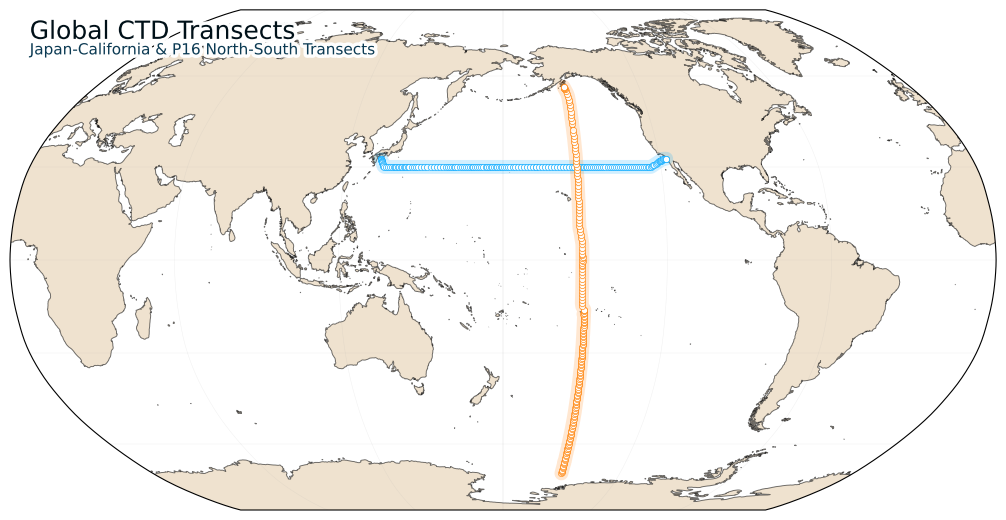

In [38]:
# ====================================================================
# 🗺️ UPDATED TRANSECT MAP: JAPAN-CA (EW) + P16 (NS)
# ====================================================================
import matplotlib.patheffects as pe  # <--- Fixes NameError
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# Gather the stations we just processed
all_transects = [
    {"lats": [s["lat"] for s in stations_ew], "lons": [s["lon"] for s in stations_ew], "color": "#00a7ff", "label": "Japan-CA"},
    {"lats": [s["lat"] for s in stations_ns], "lons": [s["lon"] for s in stations_ns], "color": "#ff7f00", "label": "P16 (NS)"}
]

# Helper to format paths
def get_path(lats, lons):
    lats = np.array(lats, dtype=float)
    lons = np.array(lons, dtype=float)
    m = np.isfinite(lats) & np.isfinite(lons)
    lats, lons = lats[m], lons[m]
    lons = ((lons + 180) % 360) - 180
    jumps = np.where(np.abs(np.diff(lons)) > 180)[0]
    l_list, la_list = lons.tolist(), lats.tolist()
    for i in jumps[::-1]:
        l_list.insert(i + 1, np.nan)
        la_list.insert(i + 1, np.nan)
    return np.array(la_list), np.array(l_list)

# Plotting
fig = plt.figure(figsize=(10, 10), facecolor="white")
ax = plt.axes(projection=ccrs.Robinson(central_longitude=180))
ax.set_global()
ax.set_facecolor("white")

# Land and Coastlines
land = cfeature.NaturalEarthFeature("physical", "land", "50m", facecolor="#efe2cf", edgecolor="none")
ax.add_feature(land, zorder=2)
ax.coastlines(resolution="50m", linewidth=0.7, alpha=0.55, zorder=3)
ax.gridlines(draw_labels=False, linewidth=0.35, alpha=0.18, zorder=1)

# Plot transects
for t in all_transects:
    la, lo = get_path(t["lats"], t["lons"])
    ax.plot(lo, la, transform=ccrs.PlateCarree(), linewidth=10, color=t["color"], alpha=0.18, solid_capstyle="round", zorder=4)
    ax.plot(lo, la, transform=ccrs.PlateCarree(), linewidth=3.2, color=t["color"], alpha=0.95, solid_capstyle="round", zorder=5)
    ax.scatter(t["lons"], t["lats"], transform=ccrs.PlateCarree(), s=20, facecolors="white", edgecolors=t["color"], linewidths=0.5, alpha=0.9, zorder=6)

# Title and Subtitle with path effects
title_fx = [pe.withStroke(linewidth=5, foreground="white", alpha=0.98)]
ax.text(0.02, 0.98, "Global CTD Transects", transform=ax.transAxes, ha="left", va="top", fontsize=18, color="#001018", path_effects=title_fx, zorder=10)
ax.text(0.02, 0.935, "Japan-California & P16 North-South Transects", transform=ax.transAxes, ha="left", va="top", fontsize=11, color="#0b3a53", path_effects=title_fx, zorder=10)

plt.tight_layout(pad=0.5)
plt.show()